# 09 · API local e caminho para produção

O modelo precisa responder em poucos milissegundos, e responder **igual** ao que foi validado no laboratório. 

Portanto, este notebook usa uma **API real**, construída com FastAPI em [`api/app.py`](../api/app.py), 
**através do HTTP** para responder às seguintes perguntas:

1. **Paridade:** o caminho online (uma transação em JSON) produz exatamente a mesma probabilidade
   que o caminho em lote usado na avaliação?
2. **Latência:** quanto tempo leva cada etapa por requisição, e onde está o gargalo?
3. **Vazão e contrato:** quantas requisições por segundo um processo aguenta, e o que acontece quando o dado chega fora do formato esperado?

**A API expõe quatro rotas:**
- `GET /saude`: *health check*, o mesmo que um balanceador de carga usaria;
- `POST /v1/fraude/avaliar`: avalia uma transação e, com `?explicar=true`, devolve também os três
  principais motivos do risco;
- `POST /v1/fraude/avaliar-lote`: avalia até 1.000 transações de uma vez, para reprocessamentos e
  *backtests*;
- `GET /docs`: documentação interativa (Swagger), gerada automaticamente a partir do contrato.

Para subir a API manualmente, basta rodar na raiz do repositório
`.venv/Scripts/python -m uvicorn api.app:app --port 8000 --no-access-log` e abrir
`http://127.0.0.1:8000/docs`. Para ser reproduzível, este notebook sobe a própria instância numa porta
separada (8001) e a desliga no fim.

In [1]:
# Configuração comum a todos os notebooks do projeto
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from fraude import config as cfg, dados, metricas, graficos as gr

gr.aplicar_estilo()
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
pd.set_option("display.max_columns", 40)

import json, math, subprocess, time
from concurrent.futures import ThreadPoolExecutor
import requests
from fraude.inferencia import ModeloFraude

def ms(v):
    """Milissegundos com vírgula decimal."""
    return f"{v:.2f} ms".replace(".", ",")

## 1. Subindo a API

O serviço carrega o artefato do modelo (`models/modelo_fraude.joblib`, com features, LightGBM, calibração
e limiar) uma vez, na inicialização, e o mantém em memória.

A saída do servidor, que inclui o log de cada decisão, vai para um
arquivo (**similar a como iria para o CloudWatch na nuvem**).

In [2]:
PORTA = 8001
URL = f"http://127.0.0.1:{PORTA}"
LOG_API = cfg.DIR_PROCESSADO / "api_decisoes.log"

def api_no_ar():
    try:
        return requests.get(f"{URL}/saude", timeout=0.5).ok
    except requests.ConnectionError:
        return False

assert not api_no_ar(), f"Já existe algo na porta {PORTA}; encerre antes de rodar o notebook."
arquivo_log = open(LOG_API, "w", encoding="utf-8")
servidor = subprocess.Popen(
    [sys.executable, "-m", "uvicorn", "api.app:app", "--host", "127.0.0.1", "--port", str(PORTA), "--no-access-log"],
    cwd=cfg.RAIZ, stdout=arquivo_log, stderr=subprocess.STDOUT)

t0 = time.time()
while not api_no_ar():
    if servidor.poll() is not None:
        raise RuntimeError(f"A API não subiu; veja {LOG_API}")
    time.sleep(0.2)
print(f"API no ar em {time.time() - t0:.1f} s".replace(".", ","))
requests.get(f"{URL}/saude").json()

API no ar em 3,6 s


{'status': 'ok',
 'versao_modelo': 'fraude-lgbm-v1',
 'limiar': 0.08765029019325718,
 'n_features': 25,
 'carregado_em': '2026-11-12T00:33:23'}

## 2. Chamada de ponta a ponta

Sorteamos 2.000 transações do período de teste, já no formato JSON
que chegaria do checkout. 

Para ilustrar, enviamos a transação
de **maior risco** da amostra pedindo a explicação.

In [3]:
base = dados.carregar_base()
teste = base[base["particao"] == "teste"].reset_index(drop=True)
artefato = ModeloFraude.carregar(cfg.ARQUIVO_MODELO)

colunas_payload = ["a", "b", "c", "d", "e", "f", "g", "h", "i", "j", "k", "l", "m", "n", "o", "p", "fecha", "monto"]
amostra = teste.sample(2000, random_state=cfg.SEED).reset_index(drop=True)
payloads = json.loads(amostra[colunas_payload].to_json(orient="records", date_format="iso"))

sessao = requests.Session()   # mantém a conexão aberta entre chamadas (keep-alive), como um cliente real
p_lote = artefato.probabilidade(amostra)
exemplo = payloads[int(np.argmax(p_lote))]
resposta = sessao.post(f"{URL}/v1/fraude/avaliar", params={"explicar": "true"}, json=exemplo)

print("Requisição:")
print(json.dumps(exemplo, indent=2, ensure_ascii=False))
print(f"\nResposta (HTTP {resposta.status_code}):")
print(json.dumps(resposta.json(), indent=2, ensure_ascii=False))

Requisição:
{
  "a": 2,
  "b": 1.0,
  "c": 10.6,
  "d": 1.0,
  "e": 0.0,
  "f": 3.0,
  "g": "BR",
  "h": 0,
  "i": "Livro O Hobbit",
  "j": "cat_8ef7164",
  "k": 0.6624346676,
  "l": 1537.0,
  "m": 0.0,
  "n": 1,
  "o": null,
  "p": "N",
  "fecha": "2020-04-12T21:14:55.000",
  "monto": 5.26
}

Resposta (HTTP 200):
{
  "probabilidade_fraude": 0.931891,
  "decisao": "REJEITAR",
  "limiar": 0.08765029019325718,
  "versao_modelo": "fraude-lgbm-v1",
  "motivos": [
    {
      "feature": "titulo_score",
      "valor": 0.276337,
      "contribuicao": 2.546
    },
    {
      "feature": "m",
      "valor": 0.0,
      "contribuicao": 1.1173
    },
    {
      "feature": "a",
      "valor": 2.0,
      "contribuicao": 0.8155
    }
  ]
}


A resposta traz a probabilidade calibrada, a decisão já aplicada com o limiar do notebook 08 e a versão
do modelo, que vai para o log de auditoria. 

Os **motivos** são as contribuições SHAP calculadas pelo
próprio LightGBM, em log-odds, e mostram quais features mais empurraram o risco para cima. 

## 3. Paridade: API × caminho em lote *(pergunta 3)*

O teste passa pela **cadeia HTTP inteira**: serialização JSON,
validação do contrato, montagem das features e modelo.

In [4]:
p_api = np.array([sessao.post(f"{URL}/v1/fraude/avaliar", json=t).json()["probabilidade_fraude"] for t in payloads])
p_api_lote = np.array([d["probabilidade_fraude"]
                       for i in range(0, len(payloads), 1000)
                       for d in sessao.post(f"{URL}/v1/fraude/avaliar-lote", json=payloads[i:i + 1000]).json()])

dec_lote = np.where(p_lote >= artefato.limiar, "REJEITAR", "APROVAR")
dec_api = np.where(p_api >= artefato.limiar, "REJEITAR", "APROVAR")
print(f"Rota unitária vs lote local:  diferença máxima {np.abs(p_api - p_lote).max():.1e}")
print(f"Rota de lote vs lote local:   diferença máxima {np.abs(p_api_lote - p_lote).max():.1e}")
print(f"Decisões idênticas: {(dec_api == dec_lote).mean():.0%}")
assert np.abs(p_api - p_lote).max() < 1e-5 and np.abs(p_api_lote - p_lote).max() < 1e-5

Rota unitária vs lote local:  diferença máxima 5.0e-07
Rota de lote vs lote local:   diferença máxima 5.0e-07
Decisões idênticas: 100%


As duas rotas da API reproduzem as probabilidades do laboratório até a **sexta casa decimal**, que é o
arredondamento da resposta, e todas as decisões coincidem. 

## 4. Latência ponta a ponta *(pergunta 7)*

Medimos não só o modelo, mas tudo o que o cliente realmente
espera, decompondo o tempo em três camadas:
- **modelo:** montar as features, rodar o LightGBM e calibrar (header `x-tempo-modelo-ms`);
- **servidor:** o modelo mais validação do JSON, roteamento e serialização da resposta (header
  `x-tempo-servidor-ms`);
- **cliente:** o tempo total da chamada, que soma rede local e o processamento do cliente HTTP.

In [5]:
def chamar(t, explicar=False):
    t0 = time.perf_counter()
    r = sessao.post(f"{URL}/v1/fraude/avaliar", params={"explicar": "true"} if explicar else None, json=t)
    total = (time.perf_counter() - t0) * 1e3
    return total, float(r.headers["x-tempo-servidor-ms"]), float(r.headers["x-tempo-modelo-ms"])

for t in payloads[:100]:          # aquecimento
    chamar(t)
lat = pd.DataFrame([chamar(t) for t in payloads], columns=["cliente", "servidor", "modelo"])
lat_exp = pd.DataFrame([chamar(t, explicar=True) for t in payloads[:500]], columns=["cliente", "servidor", "modelo"])

for camada in ["modelo", "servidor", "cliente"]:
    q = lat[camada].quantile([0.5, 0.95, 0.99])
    print(f"{camada:>9}: p50 {ms(q[0.5])} | p95 {ms(q[0.95])} | p99 {ms(q[0.99])}")
print(f"\nCom explicação (?explicar=true): p50 do cliente {ms(lat_exp['cliente'].median())} "
      f"(+{ms(lat_exp['cliente'].median() - lat['cliente'].median())})")

# Rota de lote: custo por transação quando 1.000 chegam juntas
t0 = time.perf_counter()
sessao.post(f"{URL}/v1/fraude/avaliar-lote", json=payloads[:1000])
print(f"Rota de lote: {ms((time.perf_counter() - t0) * 1e3 / 1000)} por transação (1.000 por chamada)")

   modelo: p50 1,06 ms | p95 1,92 ms | p99 2,45 ms
 servidor: p50 1,68 ms | p95 2,93 ms | p99 3,83 ms
  cliente: p50 2,68 ms | p95 4,55 ms | p99 5,91 ms

Com explicação (?explicar=true): p50 do cliente 3,90 ms (+1,22 ms)
Rota de lote: 0,07 ms por transação (1.000 por chamada)


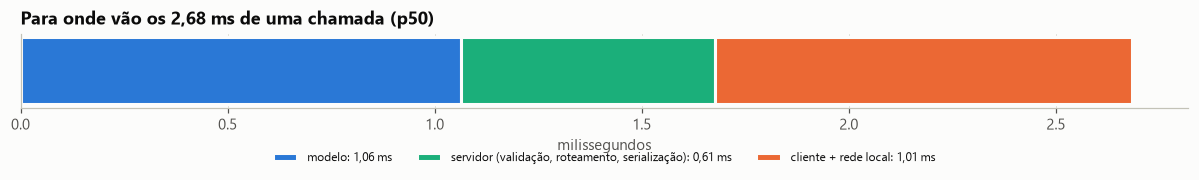

In [6]:
p50 = lat.median()
partes = {"modelo": p50["modelo"], "servidor (validação, roteamento, serialização)": p50["servidor"] - p50["modelo"],
          "cliente + rede local": p50["cliente"] - p50["servidor"]}
fig, ax = plt.subplots(figsize=(11, 2.2))
inicio = 0
for (nome, v), cor in zip(partes.items(), [gr.AZUL, gr.VERDE_AGUA, gr.LARANJA]):
    ax.barh(0, v, left=inicio, color=cor, height=0.5, label=f"{nome}: {ms(v)}", edgecolor=gr.SUPERFICIE, linewidth=2)
    inicio += v
ax.set(title=f"Para onde vão os {ms(p50['cliente'])} de uma chamada (p50)", xlabel="milissegundos", yticks=[])
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.45), ncol=3, fontsize=8)
plt.tight_layout()

Pela API, uma chamada leva **~2–3 ms** no p50. 

- O servidor, que valida o JSON contra o contrato, roteia e serializa a
resposta (~0,5 ms), e o cliente HTTP com a rede local (~0,8 ms). 

- Pedir a explicação (opcional) acrescenta ~1,7–1,8 ms,
porque o LightGBM calcula a contribuição de cada feature.

Já a rota de lote dilui os custos fixos e chega a ~0,06 ms por
transação, o que serve para reprocessar safras inteiras.

## 5. Vazão com requisições simultâneas *(pergunta 7)*

Em produção, muitos pagamentos chegam ao mesmo tempo. Disparamos as mesmas 2.000 chamadas com 1, 4 e
16 clientes simultâneos contra **um único processo** do servidor, para estimar quantas requisições
por segundo cada processo aguenta.

In [7]:
def rodada(concorrencia, itens):
    def worker(lote):
        s = requests.Session()
        out = []
        for t in lote:
            t0 = time.perf_counter()
            s.post(f"{URL}/v1/fraude/avaliar", json=t)
            out.append((time.perf_counter() - t0) * 1e3)
        return out
    lotes = [itens[i::concorrencia] for i in range(concorrencia)]
    t0 = time.perf_counter()
    with ThreadPoolExecutor(concorrencia) as ex:
        tempos = [x for parte in ex.map(worker, lotes) for x in parte]
    duracao = time.perf_counter() - t0
    return {"clientes": concorrencia, "req_por_s": len(itens) / duracao, "p95_ms": float(np.quantile(tempos, 0.95))}

vazao = pd.DataFrame([rodada(c, payloads) for c in [1, 4, 16]])
for _, r in vazao.iterrows():
    rps = f"{r['req_por_s']:,.0f}".replace(",", ".")
    print(f"{int(r['clientes']):>2} cliente(s): {rps} req/s | p95 {ms(r['p95_ms'])}")

 1 cliente(s): 413 req/s | p95 2,94 ms
 4 cliente(s): 443 req/s | p95 10,81 ms
16 cliente(s): 581 req/s | p95 33,51 ms


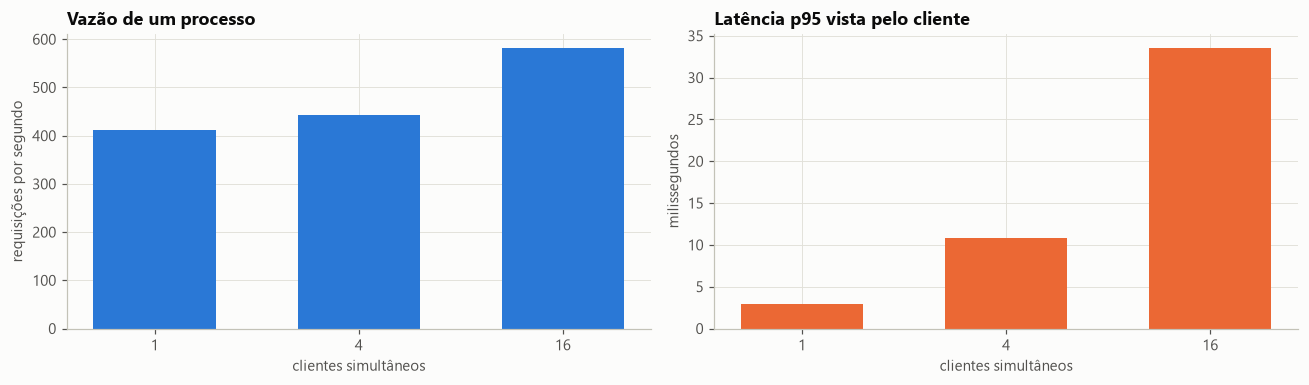

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
rotulos = vazao["clientes"].astype(str)
axes[0].bar(rotulos, vazao["req_por_s"], color=gr.AZUL, width=0.6)
axes[0].set(title="Vazão de um processo", xlabel="clientes simultâneos", ylabel="requisições por segundo")
axes[1].bar(rotulos, vazao["p95_ms"], color=gr.LARANJA, width=0.6)
axes[1].set(title="Latência p95 vista pelo cliente", xlabel="clientes simultâneos", ylabel="milissegundos")
plt.tight_layout()

Com um cliente por vez, um único processo atende **algumas centenas de requisições por segundo**
(entre ~330 e ~430 nas execuções deste notebook, porque a máquina é compartilhada) e, com 16 clientes
simultâneos, chega a **~550–570**. 

O ganho é limitado porque o Python executa o modelo uma requisição
por vez dentro do mesmo processo, então as requisições extras esperam na fila, e o p95 sobe de
poucos milissegundos para ~35 ms.

## 6. Robustez do contrato *(pergunta 4)*

A causa mais provável de um modelo funcionar no laboratório e falhar em produção é o
***training-serving skew*** (resposta 4): o dado chega à API num formato diferente do treino. 

Por isso o
contrato da API é **explícito**: valores inválidos são recusados com erro 422.

In [9]:
casos = {
    "monto negativo": {**exemplo, "monto": -10},
    "sem a data (fecha)": {k: v for k, v in exemplo.items() if k != "fecha"},
    "o = 'n' (minúsculo)": {**exemplo, "o": "n"},
    "o = '' (vazio)": {**exemplo, "o": ""},
}
for nome, t in casos.items():
    r = sessao.post(f"{URL}/v1/fraude/avaliar", json=t)
    detalhe = r.json()["detail"][0]["msg"] if r.status_code == 422 else "probabilidade " + f"{r.json()['probabilidade_fraude']:.1%}".replace(".", ",")
    print(f"{nome:<22} -> HTTP {r.status_code} | {detalhe}")

monto negativo         -> HTTP 422 | Input should be greater than 0
sem a data (fecha)     -> HTTP 422 | Field required
o = 'n' (minúsculo)    -> HTTP 422 | Input should be 'Y' or 'N'
o = '' (vazio)         -> HTTP 200 | probabilidade 93,2%


Os três primeiros casos mostram o contrato funcionando: valor negativo, data ausente e `o` minúsculo
são recusados com uma mensagem clara, que aponta o erro para o time que integra com a API. Já o texto
vazio é tratado como nulo, de propósito, porque é assim que a ausência aparece no treino.

## 7. Logs de cada decisão

Cada decisão gera uma linha JSON no log do servidor, com versão do modelo, decisão, probabilidade e
tempo, mas sem dados pessoais do payload. 

In [10]:
servidor.terminate()
servidor.wait(timeout=10)
arquivo_log.close()

linhas = [l for l in LOG_API.read_text(encoding="utf-8").splitlines() if l.startswith('{"evento"')]
print(f"{len(linhas):,} decisões registradas neste notebook. Últimas três:".replace(",", "."))
for l in linhas[-3:]:
    print(" ", l)
print("\nServidor encerrado.")

10.602 decisões registradas neste notebook. Últimas três:
  {"evento": "decisao", "versao": "fraude-lgbm-v1", "decisao": "APROVAR", "probabilidade": 0.010537, "tempo_modelo_ms": 1.123}
  {"evento": "decisao", "versao": "fraude-lgbm-v1", "decisao": "APROVAR", "probabilidade": 0.010507, "tempo_modelo_ms": 0.918}
  {"evento": "decisao", "versao": "fraude-lgbm-v1", "decisao": "REJEITAR", "probabilidade": 0.931891, "tempo_modelo_ms": 1.46}

Servidor encerrado.


## 8. Da API local para a AWS *(pergunta 8)*

Tudo o que rodou neste notebook tem um equivalente gerenciado na AWS. O diagrama mostra a arquitetura
proposta e, abaixo de cada componente, o que faz esse papel hoje, localmente.

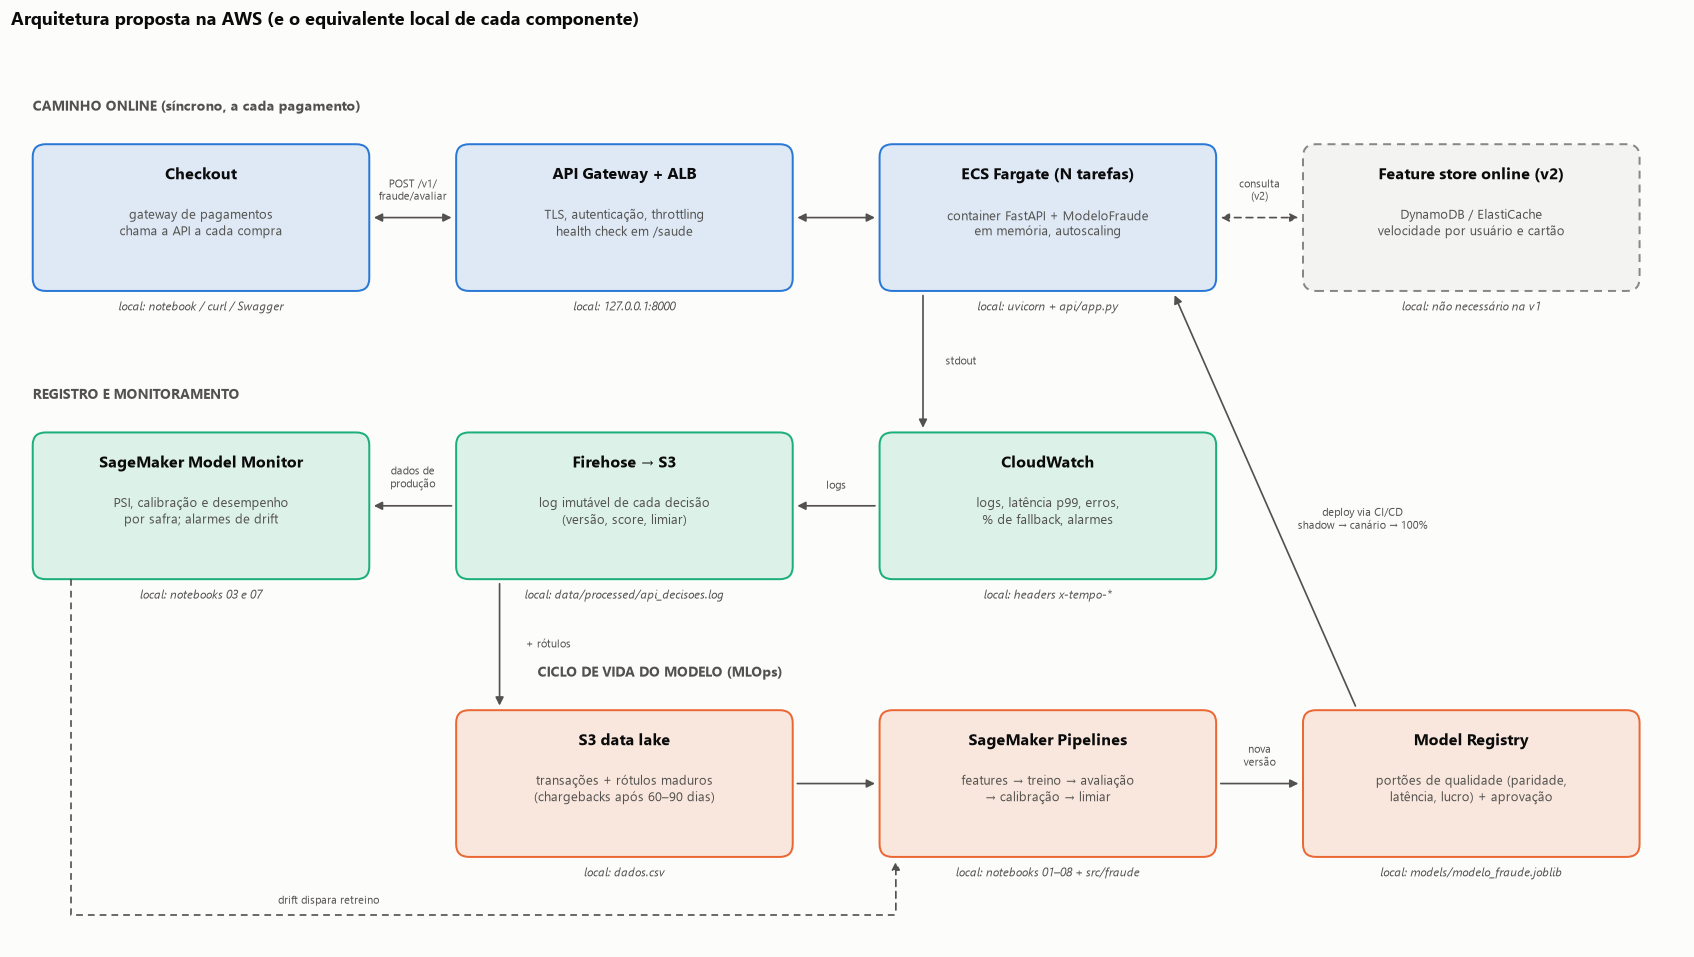

In [ ]:
from matplotlib.patches import FancyBboxPatch

fig, ax = plt.subplots(figsize=(15.5, 8.8))
ax.set_xlim(0, 15.4); ax.set_ylim(0, 8.7); ax.axis("off")
X = [0.2, 4.1, 8.0, 11.9]          # colunas
Y = {1: 6.25, 2: 3.5, 3: 0.85}     # linhas
L, A = 3.1, 1.4                    # largura e altura das caixas

def caixa(col, lin, titulo, detalhe, local, cor, tracejada=False):
    x, y = X[col], Y[lin]
    ax.add_patch(FancyBboxPatch((x, y), L, A, boxstyle="round,pad=0,rounding_size=0.12",
                                fc=cor, ec="none", alpha=0.07 if tracejada else 0.14))
    ax.add_patch(FancyBboxPatch((x, y), L, A, boxstyle="round,pad=0,rounding_size=0.12",
                                fc="none", ec=cor, lw=1.3, ls=(0, (4, 3)) if tracejada else "-"))
    ax.text(x + L / 2, y + A - 0.22, titulo, ha="center", va="top", fontsize=10.5, fontweight="bold", color=gr.TINTA)
    ax.text(x + L / 2, y + A - 0.6, detalhe, ha="center", va="top", fontsize=8.5, color=gr.TINTA_2, linespacing=1.35)
    ax.text(x + L / 2, y - 0.1, f"local: {local}", ha="center", va="top", fontsize=8, color=gr.TINTA_2, style="italic")

def ponto(col, lin, lado):
    x, y = X[col], Y[lin]
    return {"esq": (x, y + A / 2), "dir": (x + L, y + A / 2), "cima": (x + L / 2, y + A),
            "baixo": (x + L / 2, y)}[lado]

def seta(de, para, rotulo="", ls="-", duas_pontas=False, deslocamento=(0, 0.14)):
    ax.annotate("", xy=para, xytext=de, arrowprops=dict(
        arrowstyle="<|-|>" if duas_pontas else "-|>", color=gr.TINTA_2, lw=1.1, ls=ls,
        shrinkA=3, shrinkB=3, mutation_scale=11))
    if rotulo:
        mx, my = (de[0] + para[0]) / 2 + deslocamento[0], (de[1] + para[1]) / 2 + deslocamento[1]
        ax.text(mx, my, rotulo, ha="center", va="bottom", fontsize=7.5, color=gr.TINTA_2,
                bbox=dict(fc=gr.SUPERFICIE, ec="none", pad=1))

# Faixas
for lin, nome in [(1, "CAMINHO ONLINE (síncrono, a cada pagamento)"), (2, "REGISTRO E MONITORAMENTO"),
                  (3, "CICLO DE VIDA DO MODELO (MLOps)")]:
    ax.text(X[1] + 0.75 if lin == 3 else 0.2, Y[lin] + A + 0.32, nome, fontsize=9, fontweight="bold", color=gr.TINTA_2)

# Linha 1: caminho online
caixa(0, 1, "Checkout", "gateway de pagamentos\nchama a API a cada compra", "notebook / curl / Swagger", gr.AZUL)
caixa(1, 1, "API Gateway + ALB", "TLS, autenticação, throttling\nhealth check em /saude", "127.0.0.1:8000", gr.AZUL)
caixa(2, 1, "ECS Fargate (N tarefas)", "container FastAPI + ModeloFraude\nem memória, autoscaling", "uvicorn + api/app.py", gr.AZUL)
caixa(3, 1, "Feature store online (v2)", "DynamoDB / ElastiCache\nvelocidade por usuário e cartão", "não necessário na v1", gr.CINZA, tracejada=True)
# Linha 2: registro e monitoramento
caixa(0, 2, "SageMaker Model Monitor", "PSI, calibração e desempenho\npor safra; alarmes de drift", "notebooks 03 e 07", gr.VERDE_AGUA)
caixa(1, 2, "Firehose → S3", "log imutável de cada decisão\n(versão, score, limiar)", "data/processed/api_decisoes.log", gr.VERDE_AGUA)
caixa(2, 2, "CloudWatch", "logs, latência p99, erros,\n% de fallback, alarmes", "headers x-tempo-*", gr.VERDE_AGUA)
# Linha 3: ciclo de vida
caixa(1, 3, "S3 data lake", "transações + rótulos maduros\n(contestações após 60–90 dias)", "dados.csv", gr.LARANJA)
caixa(2, 3, "SageMaker Pipelines", "features → treino → avaliação\n→ calibração → limiar", "notebooks 01–08 + src/fraude", gr.LARANJA)
caixa(3, 3, "Model Registry", "portões de qualidade (paridade,\nlatência, lucro) + aprovação", "models/modelo_fraude.joblib", gr.LARANJA)

# Setas
seta(ponto(0, 1, "dir"), ponto(1, 1, "esq"), "POST /v1/\nfraude/avaliar", duas_pontas=True)
seta(ponto(1, 1, "dir"), ponto(2, 1, "esq"), duas_pontas=True)
seta(ponto(2, 1, "dir"), ponto(3, 1, "esq"), "consulta\n(v2)", ls=(0, (4, 3)), duas_pontas=True)
seta((X[2] + 0.4, Y[1]), (X[2] + 0.4, Y[2] + A), "stdout", deslocamento=(0.35, -0.05))
seta(ponto(2, 2, "esq"), ponto(1, 2, "dir"), "logs")
seta(ponto(1, 2, "esq"), ponto(0, 2, "dir"), "dados de\nprodução")
seta((X[1] + 0.4, Y[2]), (X[1] + 0.4, Y[3] + A), "+ rótulos", deslocamento=(0.45, -0.05))
seta(ponto(1, 3, "dir"), ponto(2, 3, "esq"))
seta(ponto(2, 3, "dir"), ponto(3, 3, "esq"), "nova\nversão")
seta((X[3] + 0.5, Y[3] + A), (X[2] + L - 0.4, Y[1]), "deploy via CI/CD\nshadow → canário → 100%", deslocamento=(0.9, -0.3))
# Drift detectado pelo monitor dispara um novo ciclo do pipeline (rota por baixo das caixas)
x_ini, x_fim, y_baixo = X[0] + 0.35, X[2] + 0.15, 0.3
ax.plot([x_ini, x_ini, x_fim], [Y[2], y_baixo, y_baixo], color=gr.TINTA_2, lw=1.1, ls=(0, (4, 3)))
seta((x_fim, y_baixo), (x_fim, Y[3]), ls=(0, (4, 3)))
ax.text((x_ini + X[1]) / 2 + 0.6, y_baixo + 0.08, "drift dispara retreino", ha="center", va="bottom",
        fontsize=7.5, color=gr.TINTA_2)

ax.set_title("Arquitetura proposta na AWS (e o equivalente local de cada componente)", loc="left", fontsize=12)
plt.tight_layout()